# Deep Learning, Phase 3 (Sequential Models), Day 4: Sequence Pattern Classifier
Until now we **forecast** the next value (regression). Today we **classify a whole sequence** (many-to-one): the input is a sequence, the output is one class.

Project: recognise five signal patterns (**sine, square wave, sawtooth, triangle wave, pure noise**) with random frequency, phase, amplitude and noise. Then we look **inside** the network: what do the hidden states look like for each class?

1. Generate the data  2. Model, loss and training  3. Choose between LSTM and GRU on **validation**  4. Evaluate on the test set **once**  5. Look at the mistakes  6. Visualise the hidden states


**Forecasting vs classification:** forecasting uses `MSELoss` and one number out; classification uses `CrossEntropyLoss` and one **score per class** out (the logits, no softmax inside the model).

In [ ]:
import copy, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.decomposition import PCA
sns.set_theme(style='whitegrid')
np.random.seed(42); torch.manual_seed(0)

## 1. Generate the data
Each sequence has 100 time steps. Random settings make every example different: 2 to 5 cycles, a random starting phase, a random amplitude, and Gaussian noise. The noise level `sigma` controls how hard the task is.

train (2000, 100) | validation (500, 100) | test (locked) (500, 100) | class counts in train: [400 400 400 400 400]


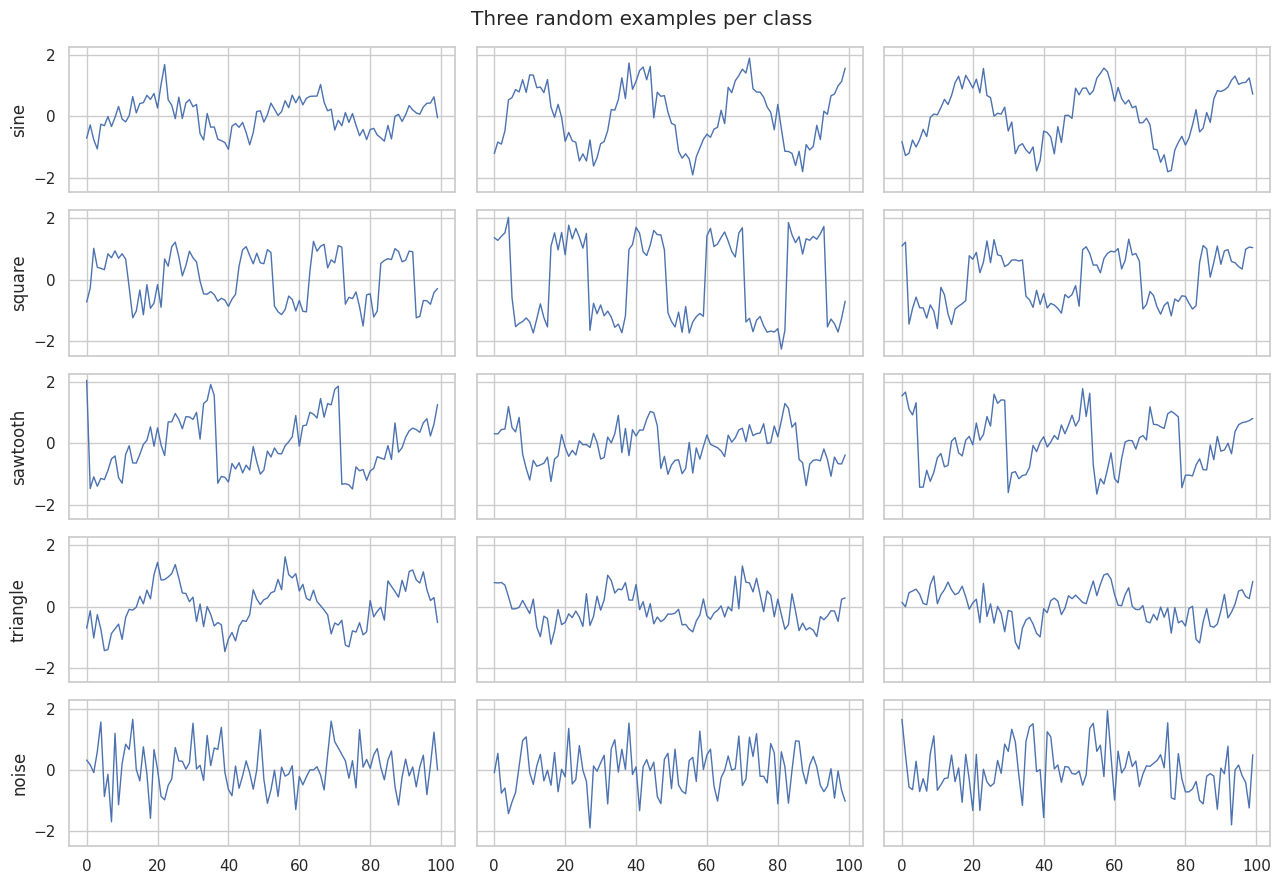

In [ ]:
CLASSES = ['sine', 'square', 'sawtooth', 'triangle', 'noise']
T = 100

def make_sequence(label, rng, sigma):
    cycles = rng.uniform(2, 5); phase = rng.uniform(0, 1); amp = rng.uniform(0.5, 1.5)
    u = (np.linspace(0, cycles, T) + phase) % 1.0                 # position inside one cycle, 0..1
    if label == 0:   base = np.sin(2 * np.pi * u)                 # sine
    elif label == 1: base = np.where(u < 0.5, 1.0, -1.0)          # square
    elif label == 2: base = 2 * u - 1                             # sawtooth
    elif label == 3: base = 1 - 4 * np.abs(u - 0.5)               # triangle
    else:            base = np.zeros(T)                           # noise only
    noise = rng.normal(0, sigma, T) if label != 4 else rng.normal(0, 0.7, T)    # the 'noise' class is pure noise
    return amp * base + noise

def make_dataset(n_per_class, seed, sigma=0.3):
    rng = np.random.default_rng(seed); X, y = [], []
    for label in range(len(CLASSES)):
        for _ in range(n_per_class): X.append(make_sequence(label, rng, sigma)); y.append(label)
    X, y = np.array(X, dtype=np.float32), np.array(y); p = rng.permutation(len(y))            # shuffling is fine here: every sequence is independent
    return X[p], y[p]

Xtr, ytr = make_dataset(400, seed=1); Xva, yva = make_dataset(100, seed=2); Xte, yte = make_dataset(100, seed=3)     # three separate generators: no overlap
print('train', Xtr.shape, '| validation', Xva.shape, '| test (locked)', Xte.shape, '| class counts in train:', np.bincount(ytr))
fig, axes = plt.subplots(5, 3, figsize=(13, 9), sharex=True, sharey=True)
for c in range(5):
    idx = np.where(ytr == c)[0][:3]
    for j, i in enumerate(idx): axes[c, j].plot(Xtr[i], lw=1); axes[c, 0].set_ylabel(CLASSES[c])
plt.suptitle('Three random examples per class'); plt.tight_layout(); plt.show()

**Note:** unlike the forecasting data, these sequences are **independent** of each other, so shuffling before the train / validation / test split is fine. (For one long time series it is **not**.) The three sets are generated with different seeds, so no sequence appears twice.

## 2. The model
Many-to-one: the RNN reads the 100 steps, we take the **last hidden state**, and a `Linear` layer turns it into 5 class scores.

In [ ]:
class SeqClassifier(nn.Module):
    def __init__(self, kind='lstm', hidden=32, n_classes=5):
        super().__init__()
        self.rnn = {'lstm': nn.LSTM, 'gru': nn.GRU}[kind](1, hidden, batch_first=True); self.fc = nn.Linear(hidden, n_classes)
    def forward(self, x, return_all=False):
        out, _ = self.rnn(x)                          # out: (batch, time, hidden)
        logits = self.fc(out[:, -1])                  # the last time step -> class scores
        return (logits, out) if return_all else logits

to_t = lambda a: torch.tensor(a)[..., None] if a.dtype == np.float32 else torch.tensor(a)
Xtr_t, ytr_t, Xva_t, yva_t, Xte_t, yte_t = map(to_t, (Xtr, ytr, Xva, yva, Xte, yte))

def train(kind, seed=0, epochs=30, lr=3e-3, batch=64, clip=1.0):
    torch.manual_seed(seed); m = SeqClassifier(kind); opt = torch.optim.Adam(m.parameters(), lr=lr); lf = nn.CrossEntropyLoss()
    hist = {'loss': [], 'val_loss': [], 'val_acc': []}; best, best_state = float('inf'), None
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(Xtr_t)); run = 0
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]; opt.zero_grad(); loss = lf(m(Xtr_t[idx]), ytr_t[idx]); loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), clip); opt.step(); run += loss.item() * len(idx)
        m.eval()
        with torch.no_grad(): lg = m(Xva_t); vl = lf(lg, yva_t).item(); va = (lg.argmax(1) == yva_t).float().mean().item()
        hist['loss'].append(run / len(perm)); hist['val_loss'].append(vl); hist['val_acc'].append(va)
        if vl < best: best, best_state = vl, copy.deepcopy(m.state_dict())
    m.load_state_dict(best_state); return m, hist

m, h = train('lstm'); print('Parameters:', sum(p.numel() for p in m.parameters()))

Parameters: 4645


## 3. Choose between LSTM and GRU on the validation set
Three seeds each. We choose the model with the **validation** data only. The test set stays locked.

,val accuracy (mean of 3 seeds),min,max
LSTM,0.821,0.818,0.824
GRU,0.893,0.884,0.904


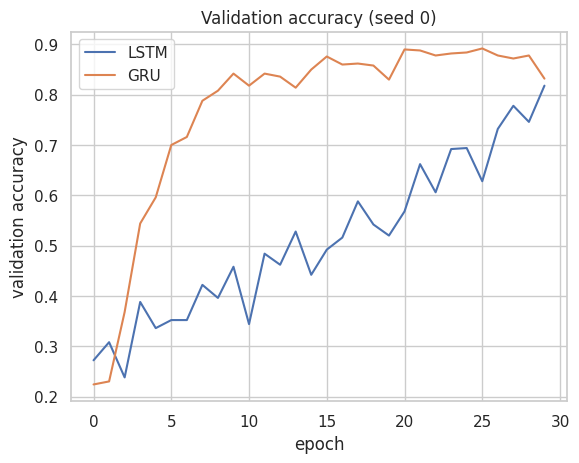

In [ ]:
results, models, hists = {}, {}, {}
for kind in ['lstm', 'gru']:
    accs = []
    for s in [0, 1, 2]:
        t0 = time.time(); m, h = train(kind, seed=s); m.eval()
        with torch.no_grad(): accs.append((m(Xva_t).argmax(1) == yva_t).float().mean().item())
        models[(kind, s)], hists[(kind, s)] = m, h
    results[kind.upper()] = {'val accuracy (mean of 3 seeds)': np.mean(accs), 'min': np.min(accs), 'max': np.max(accs)}
display(pd.DataFrame(results).T.round(3))
for kind in ['lstm', 'gru']: plt.plot(hists[(kind, 0)]['val_acc'], label=kind.upper())
plt.xlabel('epoch'); plt.ylabel('validation accuracy'); plt.legend(); plt.title('Validation accuracy (seed 0)'); plt.show()

## 4. Final evaluation on the test set (once)
We take the chosen model type and its best seed **by validation accuracy**. Change `chosen` below if your validation table points to the other model.

Chosen: GRU, seed 2 (validation accuracy 0.904)
TEST accuracy (used once): 0.918
              precision    recall  f1-score   support

        sine      0.893     0.670     0.766       100
      square      1.000     1.000     1.000       100
    sawtooth      1.000     1.000     1.000       100
    triangle      0.736     0.920     0.818       100
       noise      1.000     1.000     1.000       100

    accuracy                          0.918       500
   macro avg      0.926     0.918     0.917       500
weighted avg      0.926     0.918     0.917       500



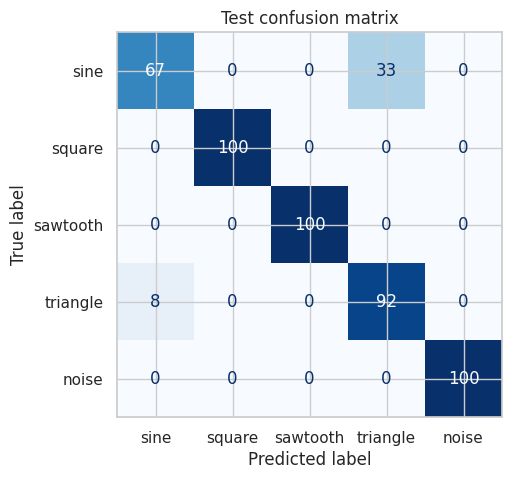

In [ ]:
chosen = max(results, key=lambda k: results[k]['val accuracy (mean of 3 seeds)']).lower()            # decided on validation only
val_accs = {s: (models[(chosen, s)].eval()(Xva_t).argmax(1) == yva_t).float().mean().item() for s in [0, 1, 2]}
best_seed = max(val_accs, key=val_accs.get); model = models[(chosen, best_seed)].eval()
print(f'Chosen: {chosen.upper()}, seed {best_seed} (validation accuracy {val_accs[best_seed]:.3f})')
with torch.no_grad(): pred = model(Xte_t).argmax(1).numpy()
print('TEST accuracy (used once):', round((pred == yte).mean(), 3)); print(classification_report(yte, pred, target_names=CLASSES, digits=3))
fig, ax = plt.subplots(figsize=(6, 5)); ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False); plt.title('Test confusion matrix'); plt.show()


## 5. Look at the mistakes

41 mistakes out of 500


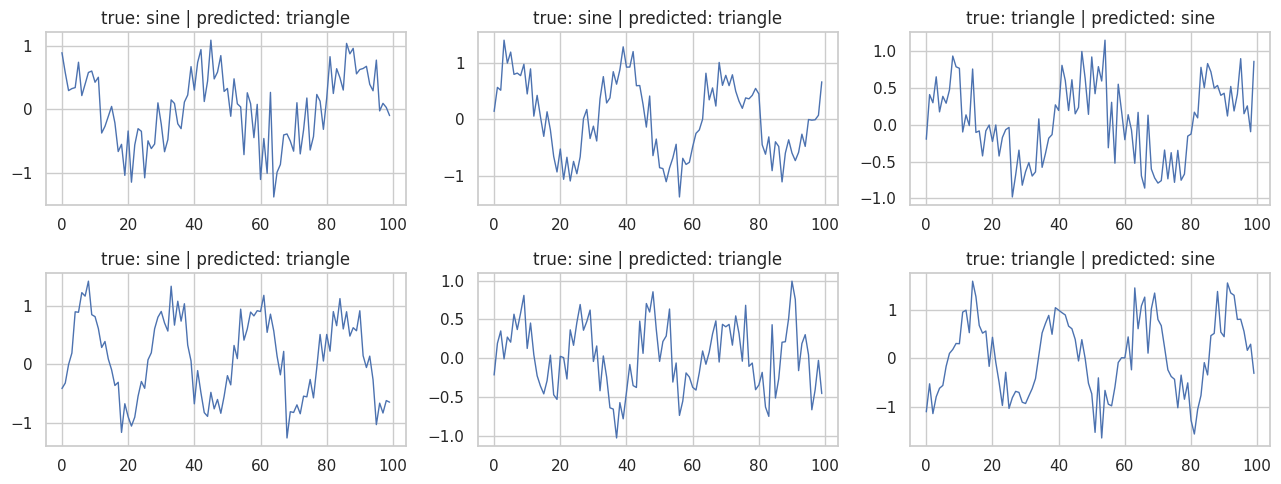

In [ ]:
wrong = np.where(pred != yte)[0]; print(len(wrong), 'mistakes out of', len(yte))
if len(wrong):
    show = wrong[:6]; fig, axes = plt.subplots(2, 3, figsize=(13, 5))
    for a, i in zip(axes.ravel(), show): a.plot(Xte[i], lw=1); a.set_title(f'true: {CLASSES[yte[i]]} | predicted: {CLASSES[pred[i]]}')
    plt.tight_layout(); plt.show()
else: print('No mistakes on the test set: try a higher noise level in make_dataset (sigma=0.8) to see harder cases.')


## 6. Visualise the hidden states
The hidden state after the last time step is the network's summary of the sequence, and the classifier only sees that. If the network has learned the patterns, the summaries of different classes should form **separate groups**.

**(a) PCA of the last hidden state.** PCA reduces the 32 numbers to 2, so we can plot them. Colour = true class (test sequences).

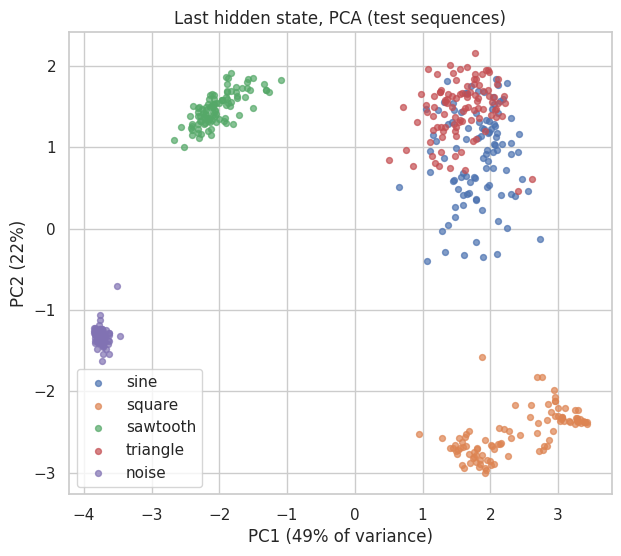

In [ ]:
with torch.no_grad(): logits, out_all = model(Xte_t, return_all=True)
H_last = out_all[:, -1].numpy(); pca = PCA(n_components=2).fit(H_last); Z = pca.transform(H_last)
plt.figure(figsize=(7, 6))
for c in range(5): plt.scatter(*Z[yte == c].T, s=18, alpha=.7, label=CLASSES[c])
plt.legend(); plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)'); plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})'); plt.title('Last hidden state, PCA (test sequences)'); plt.show()

**(b) The hidden state over time.** Heatmaps for one example of each class: rows are hidden units, columns are time steps. In the first steps the network knows little; later the pattern settles.

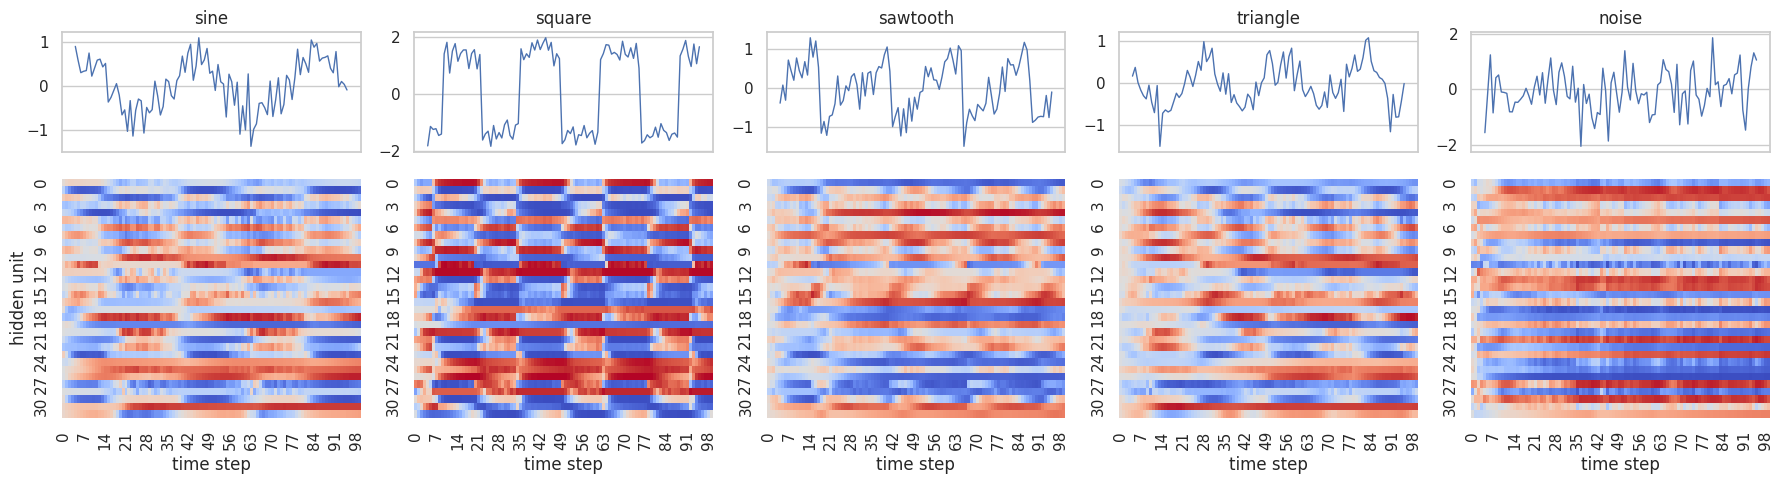

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(18, 5), gridspec_kw={'height_ratios': [1, 2]})
for c in range(5):
    i = np.where(yte == c)[0][0]; axes[0, c].plot(Xte[i], lw=1); axes[0, c].set_title(CLASSES[c]); axes[0, c].set_xticks([])
    sns.heatmap(out_all[i].numpy().T, ax=axes[1, c], cmap='coolwarm', center=0, cbar=False, vmin=-1, vmax=1); axes[1, c].set_xlabel('time step'); axes[1, c].set_ylabel('hidden unit' if c == 0 else '')
plt.tight_layout(); plt.show()

**(c) The path of the hidden state in 2D.** We project the hidden state at **every** time step with the same PCA and draw the path for one sequence per class.

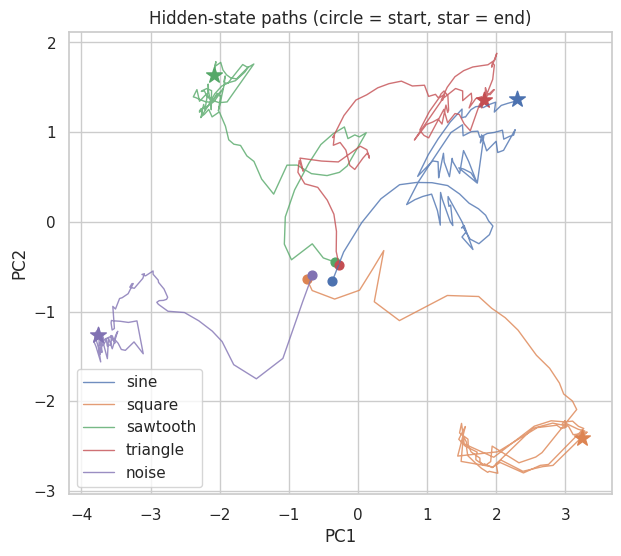

In [ ]:
plt.figure(figsize=(7, 6))
for c in range(5):
    i = np.where(yte == c)[0][0]; path = pca.transform(out_all[i].numpy()); plt.plot(*path.T, lw=1, alpha=.8, color=f'C{c}', label=CLASSES[c]); plt.scatter(*path[0], color=f'C{c}', marker='o', s=40); plt.scatter(*path[-1], color=f'C{c}', marker='*', s=140)
plt.legend(); plt.title('Hidden-state paths (circle = start, star = end)'); plt.xlabel('PC1'); plt.ylabel('PC2'); plt.show()